## Autorzy:
## Błażej Kazior 252758

# Housing Prices Competition — analiza wyników

Udział w konkursie **Housing Prices Competition for Kaggle Learn Users**. 
Zadanie polega na przewidzeniu ceny sprzedaży domu (`SalePrice`) na podstawie jego cech. Kaggle ocenia wynik średnim błędem bezwzględnym (**MAE**) w dolarach, więc im mniejsza liczba, tym lepiej.


In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

# Na Kaggle dane są w folderze konkursu, lokalnie w tym samym folderze co notebook
folder = '.'
for sciezka, foldery, pliki in os.walk('/kaggle/input'):
    if 'train.csv' in pliki:
        folder = sciezka
        break
print('Dane z folderu:', folder)

train = pd.read_csv(os.path.join(folder, 'train.csv'))
test = pd.read_csv(os.path.join(folder, 'test.csv'))
print('Dane treningowe:', train.shape, '| dane testowe:', test.shape)

Dane z folderu: /kaggle/input/competitions/home-data-for-ml-course
Dane treningowe: (1460, 81) | dane testowe: (1459, 80)


## 1. Przegląd danych

Jest 1460 domów z ceną i 1459 domów bez ceny, dla których trzeba ją przewidzieć. Najpierw sprawdzamy, jak wyglądają same ceny.

count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64


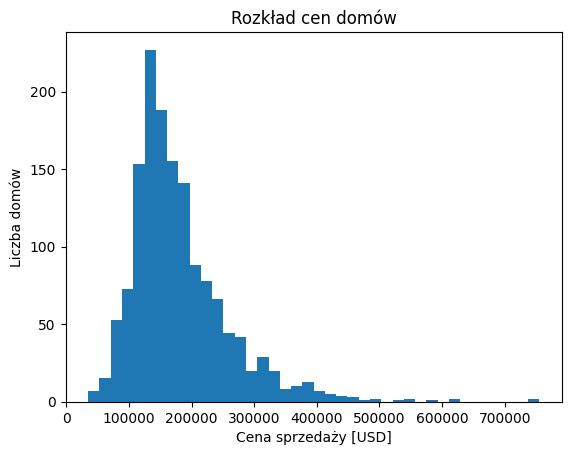

In [5]:
print(train['SalePrice'].describe().round(0))

plt.hist(train['SalePrice'], bins=40)
plt.xlabel('Cena sprzedaży [USD]')
plt.ylabel('Liczba domów')
plt.title('Rozkład cen domów')
plt.show()

**Rys. 1.** Rozkład cen sprzedaży. Większość domów kosztuje 130–215 tys. USD (mediana 163 tys.), ale jest długi „ogon” drogich domów do 755 tys. USD. Takich domów jest mało, więc model ma mniej przykładów, żeby się na nich nauczyć.

Teraz sprawdzamy, które cechy liczbowe najbardziej wiążą się z ceną. Bierzemy 25 kolumn, które kurs poleca jako bezpieczne, czyli bez braków danych i bez tekstu.

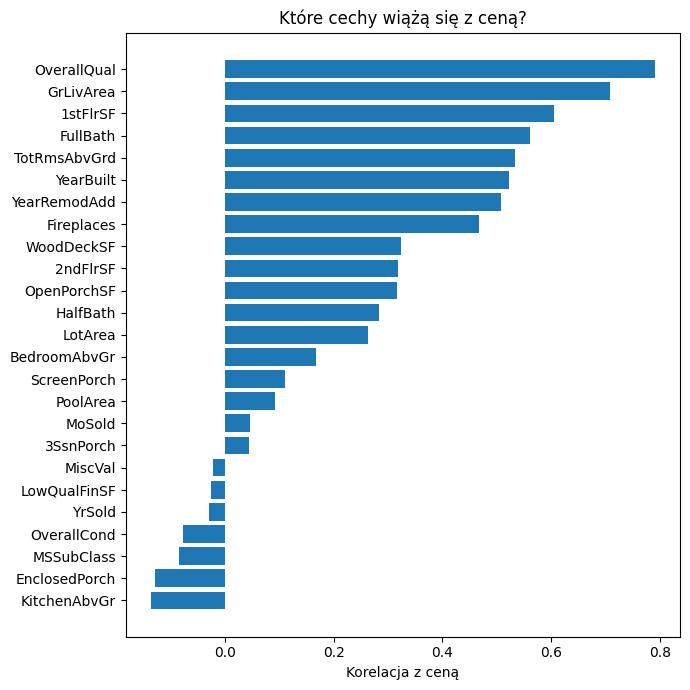

In [6]:
features_7 = ['LotArea', 'YearBuilt', '1stFlrSF', '2ndFlrSF', 'FullBath', 'BedroomAbvGr', 'TotRmsAbvGrd']

features_25 = ['MSSubClass', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
               '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'FullBath', 'HalfBath',
               'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'WoodDeckSF',
               'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
               'MiscVal', 'MoSold', 'YrSold']

# korelacja każdej cechy z ceną, od najsilniejszej
korelacja = train[features_25].corrwith(train['SalePrice']).sort_values()

plt.figure(figsize=(7, 7))
plt.barh(korelacja.index, korelacja.values)
plt.xlabel('Korelacja z ceną')
plt.title('Które cechy wiążą się z ceną?')
plt.tight_layout()
plt.show()

**Rys. 2.** Korelacja cech z ceną. Najsilniej z ceną wiąże się **OverallQual**, czyli ogólna ocena jakości domu (0,79), a potem **GrLivArea**, czyli powierzchnia mieszkalna (0,71). Żadnej z tych dwóch cech nie było w modelu z kursu, więc dodanie ich powinno wyraźnie poprawić wynik.

## 2. Model bazowy i ulepszenia

Dane treningowe dzielimy tak jak w kursie (`random_state=1`): 75% do uczenia i 25% do sprawdzania. Dzięki temu możemy porównać modele, zanim wyślemy cokolwiek na Kaggle.

Sprawdzamy cztery warianty:
1. **bazowy** — las losowy na 7 cechach z kursu (to on dał pierwszy wynik na Kaggle),
2. las losowy na 9 cechach (dodajemy OverallQual i GrLivArea),
3. las losowy na wszystkich 25 cechach,
4. **Gradient Boosting** na 25 cechach. Ten model buduje drzewa po kolei, a każde kolejne drzewo poprawia błędy poprzednich.

In [7]:
y = train['SalePrice']
features_9 = features_7 + ['OverallQual', 'GrLivArea']

warianty = [
    ('1. Las losowy, 7 cech (bazowy)', features_7, RandomForestRegressor(random_state=1)),
    ('2. Las losowy, 9 cech', features_9, RandomForestRegressor(random_state=1)),
    ('3. Las losowy, 25 cech', features_25, RandomForestRegressor(random_state=1)),
    ('4. Gradient Boosting, 25 cech', features_25, GradientBoostingRegressor(random_state=1)),
]

nazwy = []
bledy = []
for nazwa, cechy, model in warianty:
    train_X, val_X, train_y, val_y = train_test_split(train[cechy], y, random_state=1)
    model.fit(train_X, train_y)
    blad = mean_absolute_error(val_y, model.predict(val_X))
    nazwy.append(nazwa)
    bledy.append(blad)
    print(f'{nazwa}: MAE = {blad:,.0f} USD')

1. Las losowy, 7 cech (bazowy): MAE = 21,857 USD
2. Las losowy, 9 cech: MAE = 19,543 USD
3. Las losowy, 25 cech: MAE = 17,906 USD
4. Gradient Boosting, 25 cech: MAE = 16,649 USD


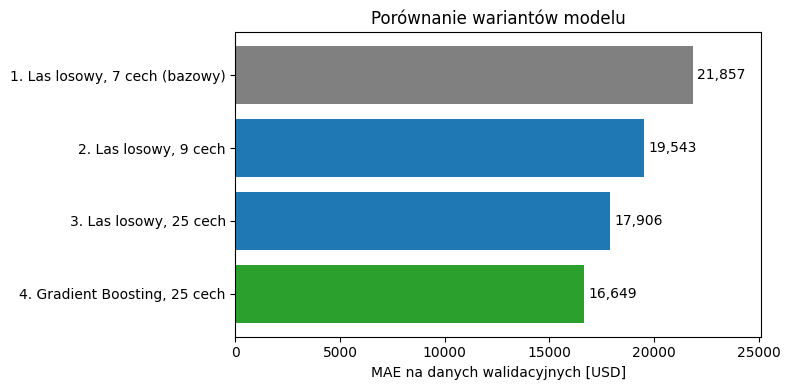

In [8]:
plt.figure(figsize=(8, 4))
plt.barh(nazwy, bledy, color=['gray', 'tab:blue', 'tab:blue', 'tab:green'])
for i, blad in enumerate(bledy):
    plt.text(blad + 200, i, f'{blad:,.0f}', va='center')
plt.xlabel('MAE na danych walidacyjnych [USD]')
plt.title('Porównanie wariantów modelu')
plt.gca().invert_yaxis()
plt.xlim(0, max(bledy) * 1.15)
plt.tight_layout()
plt.show()

**Rys. 3.** Błąd każdego wariantu na danych walidacyjnych.

| Wariant | MAE walidacja | Zmiana względem bazowego |
|---|---|---|
| 1. Las losowy, 7 cech (bazowy) | 21 857 USD | — |
| 2. Las losowy, 9 cech | 19 543 USD | −2 314 USD (−11%) |
| 3. Las losowy, 25 cech | 17 906 USD | −3 951 USD (−18%) |
| 4. Gradient Boosting, 25 cech | **16 647 USD** | **−5 210 USD (−24%)** |

- **Najwięcej dało dodanie cech, a nie zmiana modelu.** Same dwie cechy (jakość i powierzchnia) obniżyły błąd o 11%, a wszystkie 25 cech o 18%. Model z kursu nie wiedział, w jakim stanie jest dom, więc nie mógł odróżnić tanich domów od drogich o podobnym rozmiarze.
- **Zmiana modelu dała kolejne 7%.** Gradient Boosting na tych samych 25 cechach myli się o 1 259 USD mniej niż las losowy, bo każde kolejne drzewo poprawia tam, gdzie poprzednie się myliły.

## 3. Analiza najlepszego modelu

Najlepszy jest wariant 4. Sprawdzamy, na czym model opiera swoje decyzje i gdzie myli się najbardziej.

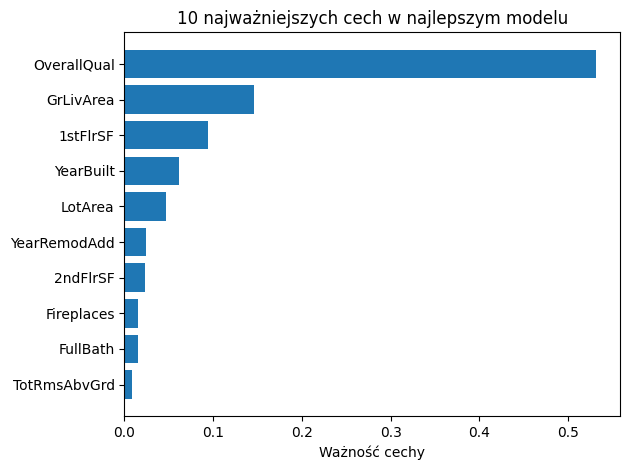

In [9]:
train_X, val_X, train_y, val_y = train_test_split(train[features_25], y, random_state=1)
najlepszy = GradientBoostingRegressor(random_state=1)
najlepszy.fit(train_X, train_y)
przewidywania = najlepszy.predict(val_X)

waznosc = pd.Series(najlepszy.feature_importances_, index=features_25).sort_values().tail(10)

plt.barh(waznosc.index, waznosc.values)
plt.xlabel('Ważność cechy')
plt.title('10 najważniejszych cech w najlepszym modelu')
plt.tight_layout()
plt.show()

**Rys. 4.** Ważność cech w modelu Gradient Boosting. **OverallQual** odpowiada za ponad połowę decyzji modelu (ok. 53%). Kolejne są powierzchnia mieszkalna (GrLivArea, ok. 15%), powierzchnia parteru (1stFlrSF, ok. 9%) i rok budowy (ok. 6%). Model „myśli” więc podobnie jak kupujący: najpierw patrzy na jakość, potem na wielkość domu.

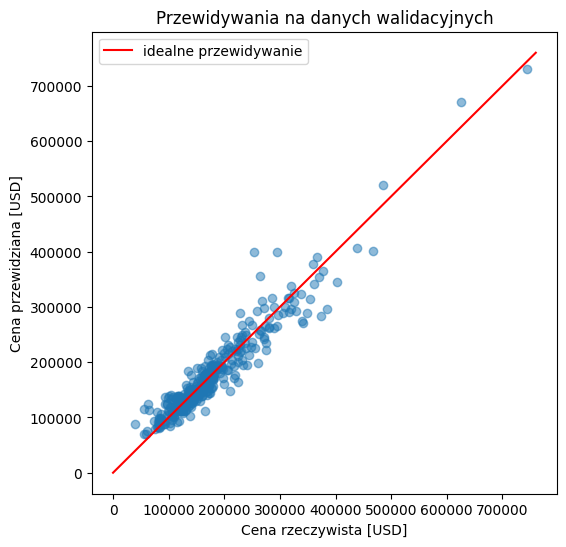

,liczba_domow,MAE_USD,blad_procentowy
grupa,,,
< 130 tys.,104,12734.0,14.4
130–165 tys.,92,11828.9,8.1
165–215 tys.,86,13805.3,7.5
> 215 tys.,83,29844.2,10.4


In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(val_y, przewidywania, alpha=0.5)
plt.plot([0, 760000], [0, 760000], color='red', label='idealne przewidywanie')
plt.xlabel('Cena rzeczywista [USD]')
plt.ylabel('Cena przewidziana [USD]')
plt.title('Przewidywania na danych walidacyjnych')
plt.legend()
plt.show()

# średni błąd w grupach cenowych
grupy = pd.cut(val_y, [0, 130000, 165000, 215000, 1e7], labels=['< 130 tys.', '130–165 tys.', '165–215 tys.', '> 215 tys.'])
bledy_grup = pd.DataFrame({'grupa': grupy, 'blad': abs(val_y - przewidywania), 'blad_proc': abs(val_y - przewidywania) / val_y * 100})
bledy_grup.groupby('grupa', observed=True).agg(liczba_domow=('blad', 'size'),
                                               MAE_USD=('blad', 'mean'),
                                               blad_procentowy=('blad_proc', 'mean')).round(1)

**Rys. 5.** Ceny przewidziane i rzeczywiste. Punkty dla tanich i średnich domów leżą blisko czerwonej linii. Przy drogich domach rozrzut jest dużo większy.

| Grupa cenowa | Liczba domów | MAE | Błąd procentowy |
|---|---|---|---|
| < 130 tys. USD | 104 | 12 700 USD | 14,4% |
| 130–165 tys. USD | 92 | 11 829 USD | 8,1% |
| 165–215 tys. USD | 86 | 13 816 USD | 7,5% |
| > 215 tys. USD | 83 | **29 864 USD** | 10,4% |

- **Drogie domy dają największe błędy w dolarach.** Ich MAE jest ponad dwa razy większe niż w pozostałych grupach. Takich domów jest mało w danych (Rys. 1), a ich cena zależy też od rzeczy, których nie mamy w 25 cechach, np. dzielnicy czy garażu.
- **Najtańsze domy mają największy błąd procentowy (14,4%).** 12 700 USD przy domu za 100 tys. to dużo. Tu też mogą pomóc cechy opisujące stan i lokalizację.
- Średnio model myli się o ok. 10% ceny domu.

## 4. Model końcowy i nowy wynik na Kaggle

Uczymy najlepszy wariant (Gradient Boosting, 25 cech) na **wszystkich** 1460 domach, bo o modelu już zdecydowaliśmy, a więcej danych daje dokładniejsze przewidywania. Potem przewidujemy ceny domów testowych i zapisujemy plik do wysłania.

In [11]:
model_koncowy = GradientBoostingRegressor(random_state=1)
model_koncowy.fit(train[features_25], y)

test_preds = model_koncowy.predict(test[features_25])

output = pd.DataFrame({'Id': test['Id'], 'SalePrice': test_preds})
output.to_csv('submission.csv', index=False)
print('Zapisano submission.csv:', output.shape)
output.head()

Zapisano submission.csv: (1459, 2)


,Id,SalePrice
0,1461,128005.168925
1,1462,158494.286573
2,1463,175166.970581
3,1464,187124.464935
4,1465,211282.820152


### Wyniki na Kaggle

| Wysłanie | Model | MAE walidacja | Wynik Kaggle (Public Score) |
|---|---|---|---|
| 1 | Las losowy, 7 cech (ćwiczenie z kursu) | 21 857 USD | 21 217,92 USD |
| 2 | Gradient Boosting, 25 cech | 16 647 USD | 17 279,99 USD |


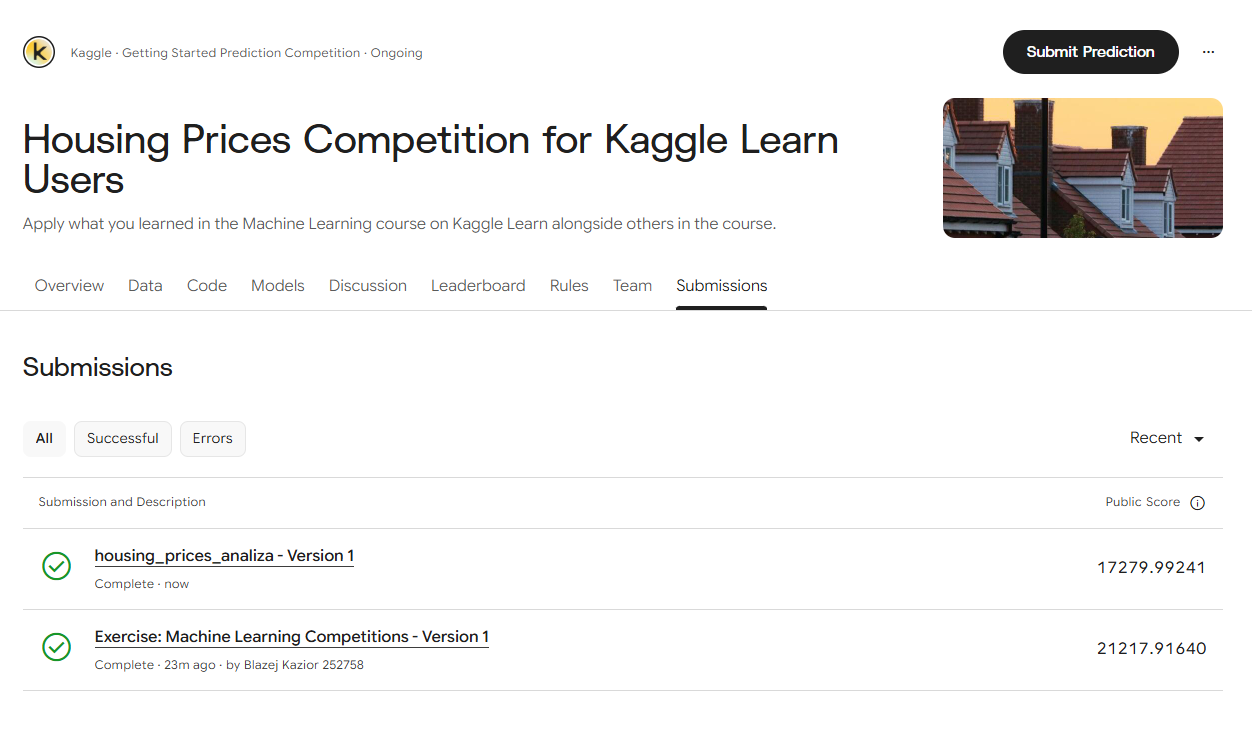

**Rys. 6.** Wyniki obu wysłań w konkursie

## 5. Wnioski

- **Najważniejsze były dane, a nie sam model.** Dodanie oceny jakości domu i jego powierzchni obniżyło błąd o 11%, a użycie wszystkich 25 cech o 18%. Model z kursu znał tylko rozmiar i liczbę pomieszczeń, więc nie odróżniał domu w dobrym stanie od zaniedbanego.
- **Lepszy model dał dodatkowe 7%.** Gradient Boosting poprawia błędy kolejnych drzew, dlatego na tych samych cechach wypadł lepiej niż las losowy. Łącznie błąd na walidacji spadł z 21 857 do 16 647 USD (−24%).
- **Największą słabością są drogie domy.** Dla domów powyżej 215 tys. USD błąd wynosi średnio ok. 30 tys. USD, bo takich przykładów jest mało, a w danych brakuje informacji o lokalizacji.
- **Co można zrobić dalej?** Dodać cechy tekstowe, np. dzielnicę (`Neighborhood`), i cechy z brakami danych, np. garaż czy piwnicę. Wymaga to uzupełniania braków i kodowania tekstu, czego uczy kurs *Intermediate Machine Learning*. Można też dostroić parametry Gradient Boostingu (liczbę drzew, głębokość).